In [150]:
words = open("names.txt","r").read().splitlines()


In [151]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [152]:
import torch

#Building dataset for training and validation
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [153]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,32),generator=g,requires_grad=True) # the character embedding matrix


In [154]:
emb = C[Xtr] # embed each character index into a 2D vector
Xtr[1,2], emb[1,2] # example of a character index and its embedding
emb.shape # (number of examples, block_size, embedding_dim)

torch.Size([182625, 3, 32])

In [155]:
import torch.nn.functional as F

W1 = torch.randn((32*3,300), generator=g, requires_grad=True)
b1 = torch.randn(300, generator=g, requires_grad=True)

W2 = torch.randn((300,27), generator=g, requires_grad=True)
b2 = torch.randn(27, generator=g, requires_grad=True)

parameters = [C, W1, b1, W2, b2]



In [166]:
sum(p.nelement()for p in parameters) # number of parameters in total

38091

In [157]:
step = []
losses = []

In [158]:
steps = 200000

for i in range(steps):
    #forward pass 
    ix = torch.randint(0,Xtr.shape[0],(32,),generator=g)
    emb = C[Xtr[ix]] # embed the characters into vectors
    logits1 = torch.tanh(emb.view(-1,32*3) @ W1 + b1) # hidden layer
    logits2 = logits1 @ W2 + b2 # output layer  
    loss = F.cross_entropy(logits2, Ytr[ix]) # loss function

    for p in parameters:
        p.grad = None
    loss.backward()
    # track stats
    #lri.append(lre[i])
    step.append(i)
    losses.append(loss.log10().item())


    # Learning rate decay
    lr = 0.1 if i < int(steps * 0.8) else 0.01    
    
    for p in parameters:
        p.data += -lr * p.grad

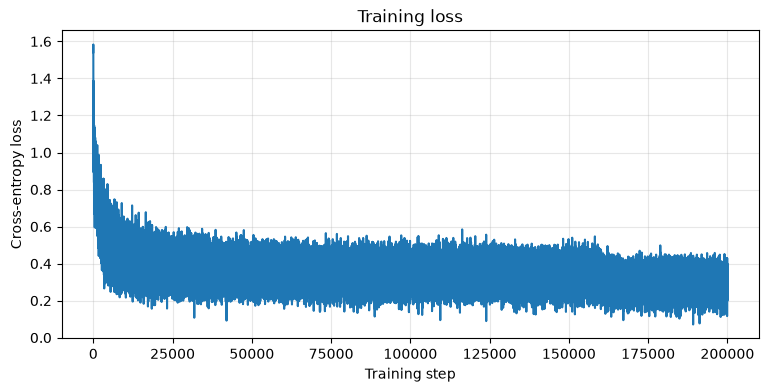

In [159]:
import matplotlib.pyplot as plt


plt.figure(figsize=(9, 4))
plt.plot(losses)
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Training loss")
plt.grid(alpha=0.3)
plt.show()

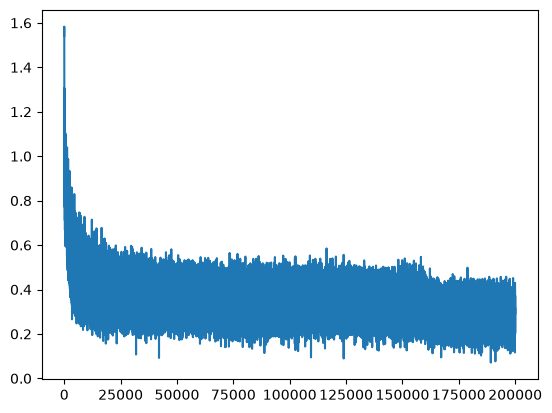

In [160]:
plt.plot(step, losses)

In [162]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 32*3 ) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1399, grad_fn=<NllLossBackward0>)

In [163]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 32*3 ) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.0088, grad_fn=<NllLossBackward0>)

In [164]:
emb = C[Xte] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 32*3 ) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Yte)
loss

tensor(2.1356, grad_fn=<NllLossBackward0>)

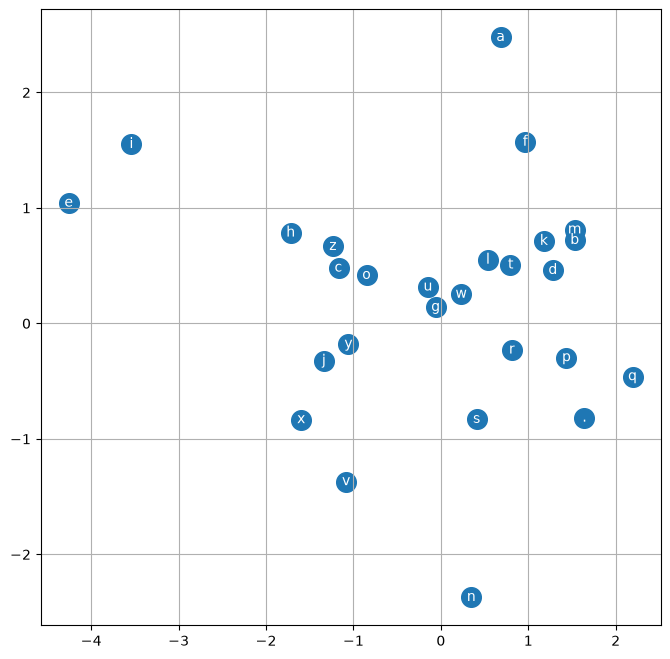

In [165]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')